# 4 SURVIVAL MODEL

**Project:** Irish Company Survival: Registrations, Cohort Survival and Prediction

**Author:** Temuulen Bulgan

### Purpose of this notebook
This notebook tests whether a company's sector, area and company type can predict if it will still be registered 5 years after registration. It compares a logistic regression and a decision tree with a simple baseline that gives every company its sector's average survival rate. The models are trained on earlier cohorts and tested on later cohorts. All model settings are fixed before the test cohorts are used.

### Input
Tables in the SQL Server database `irish_company_survival` (loaded by notebook 2).

### Output
- `data/processed/model_results.csv` (test scores for each model, for Power BI)
- Figures in `figures/` (`04_*.png`)
- Summary of findings and limitations at the end of this notebook

## Setup

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.tree import DecisionTreeClassifier
from sqlalchemy import create_engine, text

#### Connect to the database

In [3]:
# Connection to the local SQL Server database
connection_string = (
    "mssql+pyodbc://@localhost/irish_company_survival"
    "?driver=ODBC+Driver+18+for+SQL+Server"
    "&trusted_connection=yes"
    "&TrustServerCertificate=yes"
)
engine = create_engine(connection_string)

# Check the connection
with engine.connect() as conn:
    database_name = conn.execute(text("SELECT DB_NAME()")).scalar()

print("Connected to:", database_name)

Connected to: irish_company_survival


## 1. Load the data

I read one row per company from SQL, the same way as notebook 3, and add the company type. The model uses three features: sector section, area (Dublin or other counties) and company type. I use LEFT JOIN for county and sector so that companies without them are kept for now. They are removed later, when the model data is built.

In [4]:
# One row per company, with company type, county, sector and closed flag
query = """
SELECT f.company_num,
       f.reg_date,
       f.closed_date,
       t.company_type,
       c.county,
       s.section_name
FROM fact_company AS f
JOIN dim_company_type AS t ON f.company_type_id = t.company_type_id
LEFT JOIN dim_county AS c ON f.county_id = c.county_id
LEFT JOIN dim_sector AS s ON f.sector_id = s.sector_id
"""
companies = pd.read_sql(text(query), engine, parse_dates=["reg_date", "closed_date"])

# Checks against notebook 3
print("Shape:", companies.shape, "\n")
print("Missing values:")
print(companies.isna().sum(), "\n")
print("Company types:", companies["company_type"].nunique())

Shape: (512008, 6) 

Missing values:
company_num          0
reg_date             0
closed_date     305953
company_type         0
county            1822
section_name    246119
dtype: int64 

Company types: 7


The table has 512,008 companies, the same as notebook 3. Every company has a company type, and there are 7 types. 1,822 companies have no county and 246,119 have no sector section. These are removed when the model data is built in section 2.

## 2. Model data

### 2.1 Survival flag and area

The target is the same 5-year survival flag as notebook 3: a company survived if it had no closing date, or closed after its 5th anniversary. A company is eligible only if it reached 5 years by the data date. The area is Dublin or other counties, missing when the county is missing.

In [5]:
# Data date: the last date in the data, the same as notebook 3
data_date = max(companies["reg_date"].max(), companies["closed_date"].max())

# Date when each company reaches 5 years
anniversary_5y = companies["reg_date"] + pd.DateOffset(years=5)
still_registered = companies["closed_date"].isna() | (companies["closed_date"] > anniversary_5y)

companies["reg_year"] = companies["reg_date"].dt.year
companies["eligible_5y"] = anniversary_5y <= data_date
companies["survived_5y"] = (companies["eligible_5y"] & still_registered).astype(int)

# Area: Dublin, other counties, or missing when the county is missing
companies["area"] = "Other counties"
companies.loc[companies["county"] == "DUBLIN", "area"] = "Dublin"
companies.loc[companies["county"].isna(), "area"] = None

# Checks against notebook 3, section 3.1
print("Data date:", data_date.date())
print("Eligible:", companies["eligible_5y"].sum())
print("Survived:", companies["survived_5y"].sum())

Data date: 2026-10-27
Eligible: 388936
Survived: 286668


### 2.2 Companies used in the model

The model uses the same companies as notebook 3, section 5.4: full cohorts from 2016 (sector codes are reliable from then), in one of the sectors with at least 100 companies, and with an area. Every company in a full cohort is old enough for the 5-year flag, so no company is counted before its outcome is known.

In [6]:
# Full cohorts: every company in the cohort is old enough for the 5-year flag
cohort_size = companies.groupby("reg_year").size()
eligible_count = companies.groupby("reg_year")["eligible_5y"].sum()
full_cohorts = cohort_size.index[eligible_count == cohort_size]

# Full cohorts from the sector start year, the same rule as notebook 3
sector_start_year = 2016
in_period = companies["reg_year"].isin(full_cohorts) & (companies["reg_year"] >= sector_start_year)
period_data = companies[in_period]

# Sectors with at least 100 companies (missing sector is not counted)
min_companies = 100
sector_size = period_data["section_name"].value_counts()
ranked_sectors = sector_size.index[sector_size >= min_companies]

# Keep companies in a ranked sector, then companies with an area
with_sector = period_data[period_data["section_name"].isin(ranked_sectors)]
model_data = with_sector[with_sector["area"].notna()].copy()

# Checks
print("Cohorts:", model_data["reg_year"].min(), "to", model_data["reg_year"].max())
print("Companies in full cohorts from", sector_start_year, ":", len(period_data))
print("In a ranked sector:", len(with_sector))
print("Model data (also with an area):", len(model_data), "\n")
print("Categories per feature:")
print(model_data[["section_name", "area", "company_type"]].nunique(), "\n")
print("5-year survival rate:", round(model_data["survived_5y"].mean() * 100, 1), "%\n")
print(model_data.groupby("reg_year").size())

Cohorts: 2016 to 2020
Companies in full cohorts from 2016 : 110693
In a ranked sector: 110219
Model data (also with an area): 109888 

Categories per feature:
section_name    19
area             2
company_type     6
dtype: int64 

5-year survival rate: 81.9 %

reg_year
2016    20870
2017    22234
2018    22356
2019    22637
2020    21791
dtype: int64


The model data has 109,888 companies from the 2016 to 2020 cohorts, the same companies as notebook 3, section 5.4. 474 companies were removed for having no sector or a sector with fewer than 100 companies, and 331 more for having no county. There are 19 sectors, 2 areas and 6 company types: one of the 7 types has no companies in these cohorts. 81.9% of the companies survived 5 years, so a model that says "survived" for every company would be right 81.9% of the time. This is why the models are compared on AUC and Brier score, not accuracy.

### 2.3 Train, validation and test cohorts

The cohorts are split by registration year, so each model is always tested on companies registered after the ones it learned from:

- **Train** (first two cohorts): fit all models.
- **Validation** (third cohort): compare the models and choose one.
- **Test** (last two cohorts): score the chosen model once, at the end.

These settings are fixed before any model is fitted. A category with very few companies in the training set gives an unreliable estimate, so I check the company type counts in each set.

In [7]:
# Cohorts in the model data, in order
model_cohorts = sorted(model_data["reg_year"].unique())

# Split fixed in advance: 2 train cohorts, 1 validation cohort, the rest for testing
train_years = model_cohorts[:2]
validation_years = model_cohorts[2:3]
test_years = model_cohorts[3:]

# Label each company with its set
model_data["set"] = "test"
model_data.loc[model_data["reg_year"].isin(train_years), "set"] = "train"
model_data.loc[model_data["reg_year"].isin(validation_years), "set"] = "validation"

print("Train:", train_years, "| Validation:", validation_years, "| Test:", test_years, "\n")

# Companies and 5-year survival rate in each set
set_summary = model_data.groupby("set")["survived_5y"].agg(["size", "mean"])
set_summary["mean"] = (set_summary["mean"] * 100).round(1)
print(set_summary.rename(columns={"size": "companies", "mean": "survival_pct"}), "\n")

# Companies per company type in each set
pd.crosstab(model_data["company_type"], model_data["set"])

Train: [np.int32(2016), np.int32(2017)] | Validation: [np.int32(2018)] | Test: [np.int32(2019), np.int32(2020)] 

            companies  survival_pct
set                                
test            44428          86.6
train           43104          76.3
validation      22356          83.4 



set,test,train,validation
company_type,,,
DAC,1496,1505,878
Guarantee (CLG),1511,1310,681
Other,7,9,3
Private limited (LTD),40973,39639,20503
Public (PLC),21,56,23
Unlimited,420,585,268


The training set has 43,104 companies (2016 and 2017), the validation set 22,356 (2018) and the test set 44,428 (2019 and 2020). 5-year survival rises from 76.3% in the training set to 83.4% in the validation set and 86.6% in the test set. Notebook 3 (section 3.5) showed that closures fell from 2020 to 2023, so later cohorts look more likely to survive. Every model learns from the earlier cohorts, so all of them are likely to predict too low a survival rate for the later ones. Private limited companies are the large majority in every set. "Other" has only 9 companies and PLC 56 in the training set, too few for a reliable estimate.

### 2.4 Small company types

Company types with fewer than 100 companies in the training set are put into one group, "Other (small types)". The rule uses the training set only, so the validation and test cohorts play no part in the choice. The threshold is the same as for sectors.

In [8]:
# Company types with fewer than 100 companies in the training set
is_train = model_data["set"] == "train"
train_type_size = model_data.loc[is_train, "company_type"].value_counts()
small_types = train_type_size.index[train_type_size < min_companies]

# Model feature: company type, with the small types in one group
model_data["type_group"] = model_data["company_type"]
model_data.loc[model_data["company_type"].isin(small_types), "type_group"] = "Other (small types)"

print("Small types:", list(small_types), "\n")
pd.crosstab(model_data["type_group"], model_data["set"])

Small types: ['Public (PLC)', 'Other'] 



set,test,train,validation
type_group,,,
DAC,1496,1505,878
Guarantee (CLG),1511,1310,681
Other (small types),28,65,26
Private limited (LTD),40973,39639,20503
Unlimited,420,585,268


PLC and "Other" are combined into one group with 65 training companies. The model uses 5 company type groups.

## 3. Models on the validation cohort

All three models are fitted on the training cohorts and scored on the validation cohort. The model with the best validation scores is chosen. The test cohorts are not used in this section.

Each model gives every company a predicted probability of surviving 5 years. Two scores compare the predictions with what happened:

- **AUC**: the chance that a randomly picked survivor gets a higher predicted probability than a randomly picked company that closed. 0.5 is no better than guessing, 1.0 is perfect. Higher is better.
- **Brier score**: the average squared difference between the predicted probability and the outcome (1 = survived, 0 = closed). Lower is better.

### 3.1 Baseline: sector average

The baseline gives each company the 5-year survival rate of its sector in the training cohorts. A model is only useful if it beats this.

In [9]:
# Training and validation companies
train = model_data[is_train]
validation = model_data[model_data["set"] == "validation"]

# Scores for a set of predicted probabilities, as one row of a table
def score(model_name, actual, predicted):
    return {"model": model_name,
            "auc": round(roc_auc_score(actual, predicted), 3),
            "brier": round(brier_score_loss(actual, predicted), 3),
            "mean_predicted_pct": round(predicted.mean() * 100, 1),
            "actual_pct": round(actual.mean() * 100, 1)}

# Baseline: 5-year survival rate of each sector in the training cohorts
sector_rate = train.groupby("section_name")["survived_5y"].mean()

# Each validation company gets its sector's training rate
baseline_pred = validation["section_name"].map(sector_rate)

# Checks
print("Sectors with a training rate:", len(sector_rate))
print("Validation companies without a prediction:", baseline_pred.isna().sum(), "\n")

validation_scores = [score("Baseline (sector average)", validation["survived_5y"], baseline_pred)]
pd.DataFrame(validation_scores)

Sectors with a training rate: 19
Validation companies without a prediction: 0 



,model,auc,brier,mean_predicted_pct,actual_pct
0,Baseline (sector average),0.575,0.143,76.4,83.4


All 19 sectors have a training rate, so every validation company gets a prediction. The baseline has an AUC of 0.575: sector alone ranks survivors above closures only a little better than guessing. The average predicted survival is 76.4%, but 83.4% of the validation companies survived, so the baseline is 7.0 points too low. This comes from the rise in survival between the training and validation cohorts (section 2.3), not from the sectors.

### 3.2 Logistic regression

The logistic regression uses all three features: sector, area and company type group. Each feature is a category, so the model estimates one effect for each category compared with a reference category. The reference is the first category in alphabetical order. No settings are tuned.

In [10]:
# Logistic regression: 5-year survival from sector, area and company type group
formula = "survived_5y ~ C(section_name) + C(area) + C(type_group)"
logit_model = smf.logit(formula, data=train).fit()

print(logit_model.summary())

Optimization terminated successfully.
         Current function value: 0.530763
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:            survived_5y   No. Observations:                43104
Model:                          Logit   Df Residuals:                    43080
Method:                           MLE   Df Model:                           23
Date:                Mon, 09 Nov 2026   Pseudo R-squ.:                 0.03105
Time:                        12:39:26   Log-Likelihood:                -22878.
converged:                       True   LL-Null:                       -23611.
Covariance Type:            nonrobust   LLR p-value:                4.479e-296
                                                       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------
Intercept                       

The model converged. The reference categories are Accommodation and food (sector), Dublin (area) and DAC (type group). The coefficient for other counties is 0.3586 with a p-value below 0.001: companies outside Dublin have higher odds of surviving 5 years than Dublin companies in the same sector and type group, the same result as notebook 3. Agriculture (1.5634) and Construction (0.6973) have the largest positive sector coefficients and Information and communication (-0.4036) the largest negative one. Unlimited companies (0.8232) and companies limited by guarantee (0.6421) have higher odds than DACs. Mining, Public administration and Water and waste have wide confidence intervals because they have few companies. The pseudo R-squared is 0.031, so the three features explain only a small part of which companies survive.

In [11]:
# Predicted probability of surviving 5 years for each validation company
logit_pred = logit_model.predict(validation)

# Check: every validation company has a prediction
print("Validation companies without a prediction:", logit_pred.isna().sum(), "\n")

validation_scores.append(score("Logistic regression", validation["survived_5y"], logit_pred))
pd.DataFrame(validation_scores)

Validation companies without a prediction: 0 



,model,auc,brier,mean_predicted_pct,actual_pct
0,Baseline (sector average),0.575,0.143,76.4,83.4
1,Logistic regression,0.597,0.142,76.3,83.4


The logistic regression has an AUC of 0.597, against 0.575 for the baseline: adding area and company type ranks companies a little better than sector alone. The Brier score is 0.142, against 0.143. The average prediction is 76.3%, still 7.1 points below the 83.4% that survived.

### 3.3 Decision tree

The decision tree splits the companies into groups step by step, for example first by sector, then by area within a sector. This lets it find combinations that the logistic regression treats as separate effects. The settings are fixed in advance: at most 4 levels of splits (`max_depth = 4`) and at least 200 companies in each final group (`min_samples_leaf = 200`), so no group is too small to give a reliable rate.

The tree needs numbers, not text, so each category becomes its own 0/1 column.

In [12]:
# One 0/1 column per category, made once so every set has the same columns
features = pd.get_dummies(model_data[["section_name", "area", "type_group"]], dtype=int)
X_train = features[is_train]
X_validation = features[model_data["set"] == "validation"]

# Decision tree with the settings fixed in advance
tree_model = DecisionTreeClassifier(max_depth=4, min_samples_leaf=200, random_state=1)
tree_model.fit(X_train, train["survived_5y"])

# Predicted probability of surviving: the second column of predict_proba (outcome 1)
tree_pred = pd.Series(tree_model.predict_proba(X_validation)[:, 1], index=validation.index)

# Checks
print("Feature columns:", features.shape[1])
print("Final groups (leaves):", tree_model.get_n_leaves(), "\n")

validation_scores.append(score("Decision tree", validation["survived_5y"], tree_pred))
pd.DataFrame(validation_scores)

Feature columns: 26
Final groups (leaves): 9 



,model,auc,brier,mean_predicted_pct,actual_pct
0,Baseline (sector average),0.575,0.143,76.4,83.4
1,Logistic regression,0.597,0.142,76.3,83.4
2,Decision tree,0.587,0.142,76.4,83.4


The tree uses 26 columns, one for each sector, area and type group. It ends with 9 final groups, fewer than the 16 allowed, because further splits did not improve the groups or would have left fewer than 200 companies in one. The tree has an AUC of 0.587, between the baseline (0.575) and the logistic regression (0.597). Its Brier score is 0.142, the same as the logistic regression to three decimals, and its average prediction is 76.4%.

### 3.4 Choice of model

The model with the highest validation AUC is chosen. The Brier scores are almost the same for all three models, because they all share the same problem: they learn from cohorts with lower survival (section 2.3). AUC measures only the ranking, so it shows which features add information.

In [13]:
# Validation scores side by side
comparison = pd.DataFrame(validation_scores).set_index("model")

# AUC gain over the baseline
baseline_auc = comparison.loc["Baseline (sector average)", "auc"]
comparison["auc_gain"] = (comparison["auc"] - baseline_auc).round(3)

# Model with the highest validation AUC
chosen_model = comparison["auc"].idxmax()

print("Chosen model:", chosen_model, "\n")
comparison

Chosen model: Logistic regression 



,auc,brier,mean_predicted_pct,actual_pct,auc_gain
model,,,,,
Baseline (sector average),0.575,0.143,76.4,83.4,0.000
Logistic regression,0.597,0.142,76.3,83.4,0.022
Decision tree,0.587,0.142,76.4,83.4,0.012


The logistic regression is chosen. Its AUC is 0.022 above the baseline and 0.010 above the decision tree. The tree did not find combinations of sector, area and type that beat separate effects. The logistic regression is also easier to explain, because each coefficient belongs to one category. In section 4, the logistic regression and the baseline are refitted on all three earlier cohorts and scored once on the test cohorts.

## 4. Test on the later cohorts

The three models are refitted on the training and validation cohorts together, with the same features and settings as in section 3. They are then scored once on the test cohorts. The logistic regression was chosen in section 3.4; the other two are shown for comparison, and the choice does not change.

### 4.1 Refit on the earlier cohorts

In [15]:
# Earlier cohorts (training and validation) and test cohorts
is_test = model_data["set"] == "test"
earlier = model_data[~is_test]
test = model_data[is_test]

# Baseline: sector rates from the earlier cohorts
final_sector_rate = earlier.groupby("section_name")["survived_5y"].mean()
test_baseline = test["section_name"].map(final_sector_rate)

# Logistic regression: same formula
final_logit = smf.logit(formula, data=earlier).fit()
test_logit = final_logit.predict(test)

# Decision tree: same settings
final_tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=200, random_state=1)
final_tree.fit(features[~is_test], earlier["survived_5y"])
test_tree = pd.Series(final_tree.predict_proba(features[is_test])[:, 1], index=test.index)

# Checks
print("Earlier cohorts:", len(earlier), "| Test cohorts:", len(test))
print("Missing predictions:", test_baseline.isna().sum(), test_logit.isna().sum(), test_tree.isna().sum())

Optimization terminated successfully.
         Current function value: 0.503448
         Iterations 7
Earlier cohorts: 65460 | Test cohorts: 44428
Missing predictions: 0 0 0


The models are refitted on 65,460 companies from the earlier cohorts and scored on 44,428 companies from the test cohorts. Every test company has a prediction from all three models.

### 4.2 Test scores

In [16]:
# Test scores for the three models
test_scores = pd.DataFrame([
    score("Baseline (sector average)", test["survived_5y"], test_baseline),
    score("Logistic regression", test["survived_5y"], test_logit),
    score("Decision tree", test["survived_5y"], test_tree),
]).set_index("model")

# AUC gain over the baseline
test_baseline_auc = test_scores.loc["Baseline (sector average)", "auc"]
test_scores["auc_gain"] = (test_scores["auc"] - test_baseline_auc).round(3)

test_scores

,auc,brier,mean_predicted_pct,actual_pct,auc_gain
model,,,,,
Baseline (sector average),0.584,0.121,78.7,86.6,0.000
Logistic regression,0.610,0.121,78.6,86.6,0.026
Decision tree,0.597,0.121,78.6,86.6,0.013


The logistic regression has the highest test AUC, 0.610, against 0.584 for the baseline and 0.597 for the decision tree. The order is the same as on the validation cohort, and the gain over the baseline is similar (0.026 on test, 0.022 on validation), so the choice made in section 3.4 holds on new cohorts. All three models have the same Brier score, 0.121. All three predict about 78.6% survival on average, but 86.6% of the test companies survived. The models learn from earlier cohorts with lower survival, so they predict too low for later ones. This affects all three models in the same way.

### 4.3 Save the results

The validation and test scores are saved to one table for the Power BI dashboard, with one row per model and set.

In [17]:
# Validation and test scores in one table, one row per set and model
results = pd.concat([comparison, test_scores], keys=["validation", "test"], names=["set", "model"])
results = results.reset_index()

# Mark the model chosen on the validation cohort
results["chosen"] = results["model"] == chosen_model

results.to_csv("../data/processed/model_results.csv", index=False)

# Check: reload the saved file
check = pd.read_csv("../data/processed/model_results.csv")
print("Shape:", check.shape, "\n")
check

Shape: (6, 8) 



,set,model,auc,brier,mean_predicted_pct,actual_pct,auc_gain,chosen
0,validation,Baseline (sector average),0.575,0.143,76.4,83.4,0.000,False
1,validation,Logistic regression,0.597,0.142,76.3,83.4,0.022,True
2,validation,Decision tree,0.587,0.142,76.4,83.4,0.012,False
3,test,Baseline (sector average),0.584,0.121,78.7,86.6,0.000,False
4,test,Logistic regression,0.610,0.121,78.6,86.6,0.026,True
5,test,Decision tree,0.597,0.121,78.6,86.6,0.013,False


### 4.4 Chart of test AUC

The chart shows the test AUC of each model. The dashed line at 0.5 is the AUC of guessing. The chosen model is in blue.

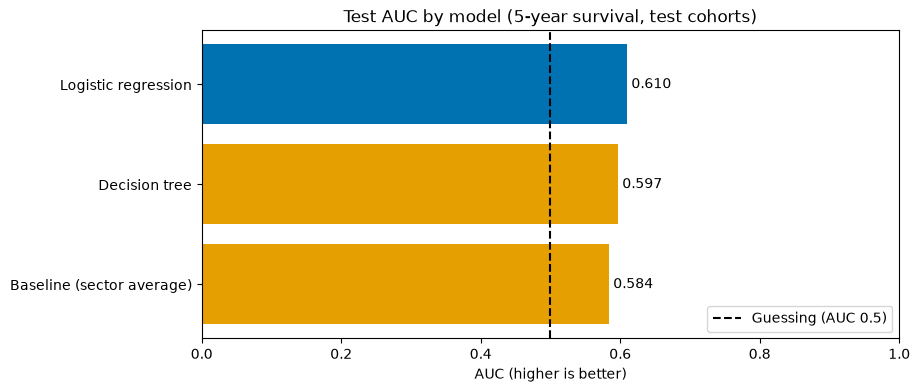

In [18]:
# Test AUC, lowest first so the highest is at the top of the chart
test_auc = test_scores["auc"].sort_values()

# Chosen model in blue, the others in orange
colours = ["#0072B2" if name == chosen_model else "#E69F00" for name in test_auc.index]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(test_auc.index, test_auc.values, color=colours)
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.axvline(0.5, color="black", linestyle="--", label="Guessing (AUC 0.5)")

ax.set_xlim(0, 1)
ax.set_title("Test AUC by model (5-year survival, test cohorts)")
ax.set_xlabel("AUC (higher is better)")
ax.legend(loc="lower right")

fig.savefig("../figures/04_test_auc_by_model.png", dpi=150, bbox_inches="tight")
plt.show()

All three models are above 0.5, so sector, area and company type say something about survival, but the bars are close together and well below 1.0. The features available in the CRO data rank companies only a little better than guessing.

## 5. Summary of findings

1. **Sector, area and company type predict 5-year survival only weakly.** The chosen logistic regression has a test AUC of 0.610, where 0.5 is guessing and 1.0 is perfect. Its pseudo R-squared on the training cohorts is 0.031 (section 3.2).

2. **The logistic regression beats the sector-average baseline, but only by a small margin.** Its AUC is 0.026 above the baseline on the test cohorts and 0.022 on the validation cohort, so the gain holds on new cohorts. The decision tree is between the two (0.597 on test) and ends with only 9 groups, so it found no combinations of sector, area and type that beat separate effects.

3. **Area and company type add information beyond sector.** Companies outside Dublin have higher odds of surviving than Dublin companies in the same sector and type group (coefficient 0.3586, p-value below 0.001), the same result as notebook 3. Unlimited companies (0.8232) and companies limited by guarantee (0.6421) have higher odds than DACs.

4. **All models predict too low a survival rate for later cohorts.** Survival rises from 76.3% in the training cohorts to 86.6% in the test cohorts. The models learn from the earlier cohorts, so they predict about 78.6% on average for the test companies. All three have the same test Brier score, 0.121. The predicted probabilities are useful for ranking companies, not as exact survival rates.

**Limitations**

- The CRO data has only three usable features for a new company. Size, owners, funding and accounts are not in the data, so a low AUC is expected.
- Only five cohorts (2016 to 2020) have both reliable sector codes and a full 5-year outcome.
- Closures fell from 2020 to 2023 (notebook 3, section 3.5), so the test cohorts may look more likely to survive than they really are.
- "Survived" means still on the register. Dormant companies count as survived.
- The rule to choose the model on AUC was stated after the validation scores were seen. The Brier scores were tied at three decimals, so the choice would not change under either score.
- Mining, Public administration and Water and waste have few companies and wide confidence intervals. PLC and "Other" company types are grouped because they are small.
- The probabilities are not adjusted for the rise in survival, so they are too low as absolute rates.